## <center> **AIC354: Machine Learning Fundamentals** </center>
## <center>**Assignment No. 3**</center>
## <center> **Applying, Evaluating, and Comparing Multiple ML Algorithms on Large Real-World Dataset** </center>
---
###          Name:  &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp;**Abdul Wahab Siddiqi**
###          Registration Number: **FA24-BSE-125 (B)**
###          Instructor: &nbsp; &nbsp; &nbsp;  &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp;**Dr. Rao Muhammad Adeel Nawab**
---

# 🔗 Live Deployment Link: https://appliance-energy-prediction-qmcmuwjb2mgfdvwtadg3yb.streamlit.app/
## 🔗 Github Link: https://github.com/Ab-Wb-Sid/Appliance-Energy-Prediction 
## 🔗 Hugging Face Link: https://huggingface.co/AbWbSid/appliance-energy-model
---

# Appliances Energy Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses.

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select **`energydata_complete.csv`** from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload `energydata_complete.csv`.

---

## Introduction

##### **Definition** A regression ML task that predicts the **energy used by household appliances (in Wh)** during a 10-minute interval, from the temperature and humidity inside the house, the weather outside, the lights energy, and the time of day.
##### **Application** Smart-home energy management, demand forecasting for electricity providers, detecting abnormal energy use, reducing electricity bills, and planning energy-saving schedules.

### Aim of This Notebook

In a single-model experiment we would train **one** algorithm and test it on **one** train/test split. This notebook answers a different question:

> **Which of 5 regression algorithms predicts appliance energy use best, and how sure can we be about that answer?**

To answer it fairly we use **K-Fold Cross Validation** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

This notebook uses the **full dataset** (about **19,700 readings**) with **10-fold cross validation**. The 5 algorithms used here are **different** from the 5 used in the Car Price Prediction System (Linear Regression, KNN, Decision Tree, Random Forest, Gradient Boosting).

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky: the result depends on *which* readings happened to land in the test set. K-Fold Cross Validation removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** on the **full dataset (~19,700 readings)**, each test fold has about 1,970 readings and each training set has about 17,760 readings:

```
Round  1:  [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  2:  [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  3:  [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  4:  [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train]
Round  5:  [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train]
Round  6:  [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train]
Round  7:  [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train]
Round  8:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train]
Round  9:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train]
Round 10:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ]
```

Every reading is used for testing **exactly once** and for training **K−1 times**.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual energy use, $\hat{y}_i$ = predicted energy use, $n$ = number of test readings
- RMSE is in the **same unit as the output (Watt-hours, Wh)**, so it reads as *"on average, predictions are off by about X Wh"*.
- **Lower RMSE = better model.** Because errors are squared, RMSE penalises **large mistakes** heavily.

## Input and Output

### Input (Features / Attributes)

| Feature | Description | Type | Unit |
|---|---|---|---|
| **lights** | Energy used by light fixtures in the house | Numerical | Wh |
| **T1 – T9** | Temperature in 9 rooms (kitchen, living room, laundry, office, bathroom, ironing room, teenager room, parents room, and outside the north side of the building) | Numerical | °C |
| **RH_1 – RH_9** | Relative humidity in the same 9 locations | Numerical | % |
| **T_out** | Outside temperature (weather station) | Numerical | °C |
| **Press_mm_hg** | Outside air pressure | Numerical | mm Hg |
| **RH_out** | Outside relative humidity | Numerical | % |
| **Windspeed** | Outside wind speed | Numerical | m/s |
| **Visibility** | Outside visibility | Numerical | km |
| **Tdewpoint** | Dew point temperature | Numerical | °C |
| **Hour** | Hour of the day (extracted from the date column) | Numerical | 0 – 23 |
| **Day of Week** | Day of the week (extracted from the date column) | Categorical | Monday, Tuesday, … |

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **Appliances** | Energy used by appliances in a 10-minute interval (Wh) | Numerical |

### Example Records

| lights | T1 | RH_1 | T_out | Windspeed | Hour | Day of Week | Appliances (Wh) |
|---|---|---|---|---|---|---|---|
| 30 | 19.89 | 47.60 | 6.60 | 7.0 | 17 | Monday | 60 |
| 30 | 19.89 | 46.69 | 6.48 | 6.7 | 17 | Monday | 60 |
| 40 | 19.89 | 46.31 | 6.37 | 6.3 | 17 | Monday | 230 |
| 40 | 19.89 | 46.07 | 6.27 | 6.0 | 17 | Monday | 580 |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | Abdul Wahab Siddiqi (Reg. No.: ____________) |
| **Course** | Machine Learning Fundamentals – AIC354, Assignment 3 |
| **Notebook Format Based On** | Car Price Prediction System by Mr. Airej Tashfeen and Dr. Rao Muhammad Adeel Nawab |
| **Program Name** | `appliances_energy_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, Matplotlib, Pickle (built-in). Exact versions are printed in Step 1. |
| **Dataset** | `energydata_complete.csv` (Appliances Energy Prediction dataset, UCI Machine Learning Repository: about 19,700 readings, 29 attributes) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data
  - **Step 2.1:** Upload the Dataset (Google Colab)
  - **Step 2.2:** Read the Dataset
- **Step 3:** Understand and Pre-process Sample Data
  - **Step 3.1:** Understand Sample Data
  - **Step 3.2:** Pre-process Sample Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
  - **Step 7.1:** Create the K-Fold Splitter
  - **Step 7.2:** Inspect the Folds
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
  - **Step 9.1:** RMSE of Each Algorithm on Each Fold
  - **Step 9.2:** Summary Comparison Table
  - **Step 9.3:** Visual Comparison
  - **Step 9.4:** Observations
- **Step 10:** Train the Final Model
  - **Step 10.1:** Select the Best Algorithm
  - **Step 10.2:** Train the Best Algorithm on All the Data
  - **Step 10.3:** Save the Trained Model
- **Step 11:** Execute the Application Phase
  - **Step 11.1:** Take Input from User
  - **Step 11.2:** Convert User Input into Feature Vector
  - **Step 11.3:** Load the Saved Model
  - **Step 11.4:** Model Prediction
- **Step 12:** Deploy the Model to the Cloud (Web App)
- **Step 13:** Execute the Feedback Phase
- **Conclusion**

# Code – Appliances Energy Prediction System
## Step 1: Import Libraries

In [26]:
# --- Core Python Libraries ---
import os
import json
import pickle
import time

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (different from the Car Price notebook) ---
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

# Show large numbers with thousands separators in pandas tables
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.1.3
  Pandas       : 2.2.3
  scikit-learn : 1.6.1
  Matplotlib   : 3.10.0


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`energydata_complete.csv`**.

If the file is already present (for example, you uploaded it earlier, or you are running the notebook on your own computer), the upload is skipped.

In [27]:
DATA_FILE = "energydata_complete.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()

    # If the browser renamed the file (e.g. 'energydata_complete (1).csv'), rename it back
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'energydata_complete.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the readings in the dataset.

In [28]:
# Load the full appliances energy dataset
energy = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {energy.shape[0]:,} readings, {energy.shape[1]} attributes")

# Preview the dataset
energy.head()

Loaded dataset: 19,735 readings, 29 attributes


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.60,19.20,44.79,19.79,44.73,19.00,...,17.03,45.53,6.60,733.50,92.00,7.00,63.00,5.30,13.28,13.28
1,2016-01-11 17:10:00,60,30,19.89,46.69,19.20,44.72,19.79,44.79,19.00,...,17.07,45.56,6.48,733.60,92.00,6.67,59.17,5.20,18.61,18.61
2,2016-01-11 17:20:00,50,30,19.89,46.30,19.20,44.63,19.79,44.93,18.93,...,17.00,45.50,6.37,733.70,92.00,6.33,55.33,5.10,28.64,28.64
3,2016-01-11 17:30:00,50,40,19.89,46.07,19.20,44.59,19.79,45.00,18.89,...,17.00,45.40,6.25,733.80,92.00,6.00,51.50,5.00,45.41,45.41
4,2016-01-11 17:40:00,60,40,19.89,46.33,19.20,44.53,19.79,45.00,18.89,...,17.00,45.40,6.13,733.90,92.00,5.67,47.67,4.90,10.08,10.08


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [29]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns).
2. Showing the total number of instances (rows).
3. Showing how many values are missing in each attribute.
"""

print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(energy.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(energy))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = energy.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")


Attributes in Sample Data:

['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Number of Instances in Sample Data:

19735

Missing Values in Each Attribute:

No missing values


### Understanding the Output (Appliances)

Before choosing an evaluation measure, it is important to look at the **range of the output**. Appliance energy use in this dataset is **highly skewed**: in most 10-minute intervals the appliances use a small amount of energy (often 50–100 Wh), but there are occasional **spikes** of several hundred Wh when heavy appliances are switched on (the maximum is over 1,000 Wh).

In [30]:
# Summary statistics of the appliance energy use (Wh)
energy_summary = energy["Appliances"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
energy_summary.to_frame(name="Appliances (Wh)")

,Appliances (Wh)
count,"19,735.00"
mean,97.69
std,102.52
min,10.00
25%,50.00
50%,60.00
75%,100.00
95%,330.00
99%,576.60
max,"1,080.00"


> **Why this matters for RMSE:** RMSE squares each error, so **a few badly predicted spikes can raise the RMSE more than thousands of well-predicted ordinary readings**. Keep this in mind when reading the results: a large RMSE does not necessarily mean the model is bad for *typical* readings.
>
> In this notebook we predict the energy use directly **in Wh**, which is easy to understand and keeps the RMSE in the original unit.

## Step 3.2: Pre-process Sample Data

In [31]:
"""
Pre-processing steps:
---------------------
1. Convert the 'date' column from text to a real date-and-time value, so that we can
   extract the hour and the day of the week from it in Step 4.
2. Remove duplicate rows (the same reading listed more than once).
   Duplicates are harmful in cross validation: a reading could appear in BOTH the
   training folds and the test fold, so the model would be tested on a reading it has
   already seen, and the RMSE would look better than it really is.
3. Sort the readings by date (they are already in time order; this just makes sure).
4. Missing NUMERIC values are NOT filled here. If there are any, they are filled
   inside the pipeline in Step 5, using only the training folds.
"""

energy["date"] = pd.to_datetime(energy["date"])

rows_before = len(energy)
energy = energy.drop_duplicates().sort_values("date").reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(energy):,}")
print(f"Instances remaining   : {len(energy):,}")
print(f"Date range            : {energy['date'].min()}  to  {energy['date'].max()}")

Duplicate rows removed: 0
Instances remaining   : 19,735
Date range            : 2016-01-11 17:00:00  to  2016-05-27 18:00:00


# Step 4: Feature Extraction

The **date** column cannot be used by an algorithm directly, so we **extract two useful features** from it:

- **Hour** (0 – 23): energy use follows a daily routine (low at night, higher in the evening).
- **Day of Week** (Monday – Sunday): weekdays and weekends have different routines.

We **do not use** the columns `rv1` and `rv2`: they are **random numbers** added by the dataset creators to test whether a model can ignore useless features. They carry no real information.

Then we separate the **input (X)** from the **output (y)**.

In [32]:
# Extract new features from the date column
energy["Hour"] = energy["date"].dt.hour
energy["Day of Week"] = energy["date"].dt.day_name()

numeric_features = (
    ["lights"]
    + [f"T{i}" for i in range(1, 10)]
    + [f"RH_{i}" for i in range(1, 10)]
    + ["T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint", "Hour"]
)
categorical_features = ["Day of Week"]
target = "Appliances"

# Input features (X) and output (y)
X = energy[numeric_features + categorical_features]
y = energy[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of readings: {len(X):,}")

X.head()

Input features (X): 27 columns -> ['lights', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'Hour', 'Day of Week']
Output (y)        : Appliances
Number of readings: 19,735


,lights,T1,T2,T3,T4,T5,T6,T7,T8,T9,...,RH_8,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Hour,Day of Week
0,30,19.89,19.20,19.79,19.00,17.17,7.03,17.20,18.20,17.03,...,48.90,45.53,6.60,733.50,92.00,7.00,63.00,5.30,17,Monday
1,30,19.89,19.20,19.79,19.00,17.17,6.83,17.20,18.20,17.07,...,48.86,45.56,6.48,733.60,92.00,6.67,59.17,5.20,17,Monday
2,30,19.89,19.20,19.79,18.93,17.17,6.56,17.20,18.20,17.00,...,48.73,45.50,6.37,733.70,92.00,6.33,55.33,5.10,17,Monday
3,40,19.89,19.20,19.79,18.89,17.17,6.43,17.13,18.10,17.00,...,48.59,45.40,6.25,733.80,92.00,6.00,51.50,5.00,17,Monday
4,40,19.89,19.20,19.79,18.89,17.20,6.37,17.20,18.10,17.00,...,48.59,45.40,6.13,733.90,92.00,5.67,47.67,4.90,17,Monday


# Step 5: Build the Pre-processing Pipeline

Machine learning algorithms need numbers, and some algorithms (Ridge, SVR, Neural Network) are sensitive to the scale of each feature. The pipeline does three things:

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | So that *Press_mm_hg* (about 750) does not dominate *Windspeed* (about 4) |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns. Unlike label encoding, it does not invent a fake order such as *Monday < Tuesday* |

### Why put pre-processing *inside* the pipeline?

If the scaler and imputer were fitted on the **whole** dataset before splitting, the cross validation would suffer from **data leakage**: the scaler and imputer would "see" the test fold.

By placing them inside the pipeline, the cross validation loop in Step 8 **re-fits them on the training folds only** in every round, and then applies them to the test fold. This is exactly what happens in the real world, where a model never sees future data during training.

`handle_unknown="ignore"` means that if a test fold contains a category that never appeared in the training folds, the model still works and simply treats it as "no known category".

In [33]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lights', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6',
                                  'T7', 'T8', 'T9', 'RH_1', 'RH_2', 'RH_3',
                                  'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8',
                                  'RH_9', 'T_out', 'Press_mm_hg', 'RH_out',
                                  'Windspeed', 'Visibility', 'Tdewpoint',
                                  'Hour']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Day of Week'])])

# Step 6: Define the 5 Regression Algorithms

We compare five algorithms that are **not** used in the Car Price Prediction System. They cover linear, kernel-based, ensemble and neural network approaches:

| # | Algorithm | How it predicts the energy use |
|---|---|---|
| 1 | **Ridge Regression** | A linear model (weighted sum of the features) with a **penalty on large weights**, which keeps the model stable when many features are correlated (e.g. T1…T9 are strongly related) |
| 2 | **Support Vector Regression (SVR)** | Fits a smooth, non-linear curve (RBF kernel) so that most readings lie within a small margin of the curve |
| 3 | **Extra Trees** | Builds 100 decision trees with **random split points** and averages their predictions |
| 4 | **AdaBoost** | Builds many small trees one after another, giving **more weight to the readings that earlier trees predicted badly** |
| 5 | **Neural Network (MLP)** | A multi-layer perceptron: layers of connected neurons that learn a non-linear relationship |

All algorithms use (almost) their **default settings** (no hyper-parameter tuning), so the comparison stays simple and fair. `random_state=42` makes the results reproducible.

Two settings differ from the defaults, with a reason:
- **SVR `C=100`**: the output (Wh) has a large scale (up to 1,000+). With the default `C=1` the SVR curve is too stiff and under-fits.
- **MLP `max_iter=500, early_stopping=True`**: gives the network enough training rounds, and stops automatically when it stops improving (this also avoids over-fitting).

In [34]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Support Vector Regression": SVR(kernel="rbf", C=100),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=42),
    "Neural Network (MLP)": MLPRegressor(hidden_layer_sizes=(100,), max_iter=500,
                                         early_stopping=True, random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Support Vector Regression
  3. Extra Trees
  4. AdaBoost
  5. Neural Network (MLP)


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the readings first. The dataset is sorted by time, so without shuffling a fold could contain only readings from one single month.
- `random_state=42`: the **same folds are used for all 5 algorithms**. Every algorithm is tested on exactly the same readings, which makes the comparison fair.

> **Note:** the readings are taken every 10 minutes, so neighbouring readings are very similar to each other. Because the folds are shuffled, a test reading usually has near-identical neighbours in the training folds, which makes the RMSE **somewhat more optimistic** than it would be for truly future data. The comparison between the algorithms is still fair, because all 5 are tested in exactly the same way.

In [35]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

Let's check how many readings are used for training and testing in each round.

In [36]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Readings": len(train_index),
        "Testing Readings": len(test_index),
        "Avg Energy of Test Readings (Wh)": y.iloc[test_index].mean(),
        "Highest Energy in Test Fold (Wh)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Readings,Testing Readings,Avg Energy of Test Readings (Wh),Highest Energy in Test Fold (Wh)
Fold (Round),,,,
1,17761,1974,93.04,770
2,17761,1974,100.28,900
3,17761,1974,99.50,890
4,17761,1974,102.30,1070
5,17761,1974,96.41,910
6,17762,1973,95.40,870
7,17762,1973,101.54,1080
8,17762,1973,94.29,880
9,17762,1973,97.10,860


Notice that the **highest energy reading** is different in each fold. A fold that happens to contain several large spikes will usually have a **higher RMSE**, because of the squaring explained in Step 3.1.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds,
3. **predict** the energy use of the readings in the test fold,
4. calculate the **RMSE** for that fold.

### Progress Bar (tqdm)

`tqdm` is a library that shows a **progress bar** while a loop runs. It is already installed in Google Colab. There is one step for each algorithm on each fold, so the bar has **5 × 10 = 50 steps**. While the cell runs, the bar looks like this:

```
Extra Trees, fold 2/10:  64%|██████    | 32/50 [00:35<00:20,  1.10fold/s]
```

| Part of the bar | Meaning |
|---|---|
| `Extra Trees, fold 2/10` | The algorithm and fold being trained right now |
| `64%` and `32/50` | How much of the work is done (steps done / total steps) |
| `00:35` (before `<`) | **Elapsed time**: time spent so far (minutes:seconds) |
| `00:20` (after `<`) | **Remaining time**: estimated time left (minutes:seconds) |
| `1.10fold/s` | Speed: folds per second (or `s/fold`, seconds per fold, when it is slow) |

> The remaining time is an **estimate** based on the average speed so far. Some algorithms are much slower than others, so the estimate goes up and down as each algorithm runs.
>
> ⏱ **This step takes several minutes in Colab.** Support Vector Regression and the Neural Network are usually the slowest, because SVR compares every reading with many others, and the network is trained for many rounds in each of the 10 folds.

In [12]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<27} -> mean RMSE = {fold_rmse[name].mean():>8,.2f} Wh   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

Support Vector Regression, fold 1/10:  20%|██        | 10/50 [00:01<00:10,  3.69fold/s]

Ridge Regression            -> mean RMSE =    93.22 Wh   (1.8 s)


Extra Trees, fold 1/10:  40%|████      | 20/50 [04:38<13:26, 26.88s/fold]               

Support Vector Regression   -> mean RMSE =    88.24 Wh   (276.9 s)


AdaBoost, fold 1/10:  60%|██████    | 30/50 [06:37<04:06, 12.35s/fold]    

Extra Trees                 -> mean RMSE =    62.05 Wh   (118.8 s)


Neural Network (MLP), fold 1/10:  80%|████████  | 40/50 [06:56<00:22,  2.29s/fold]

AdaBoost                    -> mean RMSE =   131.39 Wh   (19.4 s)


Neural Network (MLP), fold 2/10:  82%|████████▏ | 41/50 [07:36<02:00, 13.38s/fold]/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
Neural Network (MLP), fold 7/10:  92%|█████████▏| 46/50 [10:53<02:20, 35.17s/fold]/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
Neural Network (MLP), fold 8/10:  94%|█████████▍| 47/50 [11:40<01:56, 38.75s/fold]/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
Done: 100%|██████████| 50/50 [13:37<00:00, 16.35s/fold]

Neural Network (MLP)        -> mean RMSE =    83.62 Wh   (400.6 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation, and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

**How to read it:** count the green cells in each column to see how many folds each algorithm **won**. The algorithm with the best *average* does not always win every fold, which is why we compare the mean over all folds (Step 9.2) rather than trusting any single fold.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("{:,.2f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Support Vector Regression,Extra Trees,AdaBoost,Neural Network (MLP)
Fold,,,,,
Fold 1,85.14,79.80,54.37,148.92,78.16
Fold 2,96.21,91.43,63.54,122.05,86.14
Fold 3,95.31,91.12,62.20,130.99,85.45
Fold 4,103.86,99.76,70.57,135.42,94.65
Fold 5,93.98,90.57,64.37,142.70,85.96
Fold 6,89.44,83.06,58.24,99.33,78.32
Fold 7,96.35,91.25,64.25,137.15,84.60
Fold 8,88.11,81.73,55.54,131.06,76.54
Fold 9,94.18,88.83,63.74,119.17,84.42


## Step 9.2: Summary Comparison Table

This is the main result of the notebook. For each algorithm:

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** the algorithms (lower is better) |
| **Std RMSE** | Standard deviation over the folds. A **small value means the algorithm is consistent**; a large value means its performance depends on which readings it gets |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Energy** | Mean RMSE divided by the average appliance energy use. This puts the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_energy = y.mean()

summary = pd.DataFrame({
    "Mean RMSE (Wh)": per_fold_table.mean(),
    "Std RMSE (Wh)": per_fold_table.std(),
    "Best Fold RMSE (Wh)": per_fold_table.min(),
    "Worst Fold RMSE (Wh)": per_fold_table.max(),
    "RMSE as % of Avg Energy": per_fold_table.mean() / average_energy * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE (Wh)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average appliance energy use in this data: {average_energy:,.2f} Wh\n")

rmse_columns = ["Mean RMSE (Wh)", "Std RMSE (Wh)", "Best Fold RMSE (Wh)", "Worst Fold RMSE (Wh)"]
(summary.style
    .format({**{c: "{:,.2f}" for c in rmse_columns},
             "RMSE as % of Avg Energy": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE (Wh)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average appliance energy use in this data: 97.69 Wh



,Rank,Mean RMSE (Wh),Std RMSE (Wh),Best Fold RMSE (Wh),Worst Fold RMSE (Wh),RMSE as % of Avg Energy,Time (s)
Algorithm,,,,,,,
Extra Trees,1,62.05,4.79,54.37,70.57,63.5%,118.78
Neural Network (MLP),2,83.62,5.26,76.54,94.65,85.6%,400.56
Support Vector Regression,3,88.24,5.95,79.80,99.76,90.3%,276.86
Ridge Regression,4,93.22,5.34,85.14,103.86,95.4%,1.79
AdaBoost,5,131.39,14.89,99.33,148.92,134.5%,19.40


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better). The black whisker shows ± 1 standard deviation across the 10 folds.

**Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how spread out each algorithm's results are.

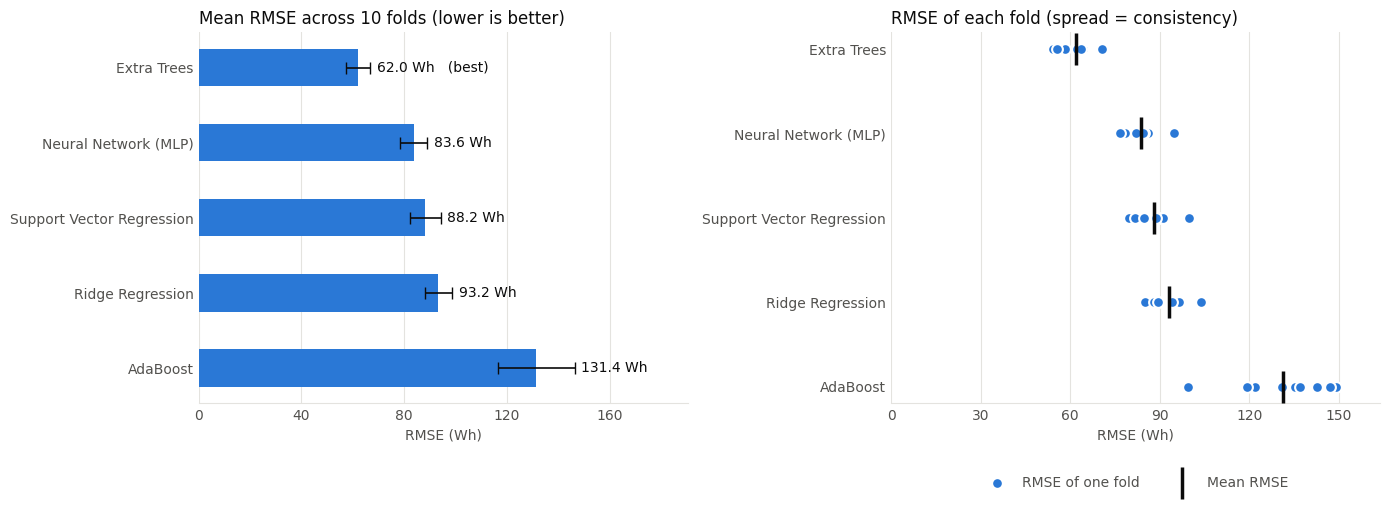

In [15]:
# Chart colours: one blue for the data, dark/grey text, light grid
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
wh_format = FuncFormatter(lambda value, _: f"{value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(wh_format)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE (Wh)"]
stds = summary["Std RMSE (Wh)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"{means[name]:,.1f} Wh" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (Wh)", color=MUTED_TEXT)

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (Wh)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

The observations below are **generated automatically from the results of your own run**, so they always match the tables and charts above.

In [16]:
best = summary.index[0]
second = summary.index[1]
worst = summary.index[-1]
gap_best_second = summary.loc[second, "Mean RMSE (Wh)"] - summary.loc[best, "Mean RMSE (Wh)"]
fold_wins = per_fold_table.idxmin(axis=1).value_counts()
hardest_fold = per_fold_table.mean(axis=1).idxmax()
easiest_fold = per_fold_table.mean(axis=1).idxmin()
slowest = summary["Time (s)"].idxmax()
fastest = summary["Time (s)"].idxmin()

print("Observations from this run")
print("==========================\n")

print(f"1. {best} has the lowest mean RMSE ({summary.loc[best, 'Mean RMSE (Wh)']:,.2f} Wh), "
      f"followed by {second} ({summary.loc[second, 'Mean RMSE (Wh)']:,.2f} Wh).")
if gap_best_second < summary.loc[best, "Std RMSE (Wh)"]:
    print(f"   The gap between them ({gap_best_second:,.2f} Wh) is smaller than the fold-to-fold "
          f"standard deviation, so the two are close to a tie.")
else:
    print(f"   The gap between them ({gap_best_second:,.2f} Wh) is larger than the fold-to-fold "
          f"standard deviation, so the best algorithm is clearly ahead.")

print(f"\n2. {worst} has the highest mean RMSE ({summary.loc[worst, 'Mean RMSE (Wh)']:,.2f} Wh).")

print(f"\n3. Best algorithm in most folds: {fold_wins.index[0]} "
      f"(won {fold_wins.iloc[0]} of {K} folds).")

print(f"\n4. Hardest fold for all algorithms: {hardest_fold}; easiest fold: {easiest_fold}. "
      f"Folds with large energy spikes give a higher RMSE because errors are squared (Step 3.1).")

print(f"\n5. Context for the RMSE: the average energy use is {average_energy:,.1f} Wh, but the standard deviation of "
      f"the real values is {y.std():,.1f} Wh. A model that always predicted the average would have an RMSE of about "
      f"{y.std():,.1f} Wh, so an algorithm is only useful if its RMSE is clearly below that value.")
print(f"   Best algorithm: {summary.loc[best, 'RMSE as % of Avg Energy']:.1f}% of the average energy use.")

print(f"\n6. Accuracy vs. speed: {fastest} is the fastest ({summary.loc[fastest, 'Time (s)']:.1f} s) and "
      f"{slowest} is the slowest ({summary.loc[slowest, 'Time (s)']:.1f} s). "
      f"In a real project this trade-off matters.")

print("\n7. Appliance energy use depends on human behaviour (when people cook, wash or switch on heavy "
      "appliances), which the temperature and humidity sensors can only reflect indirectly. "
      "This is why even the best model still has a fairly large error.")

Observations from this run

1. Extra Trees has the lowest mean RMSE (62.05 Wh), followed by Neural Network (MLP) (83.62 Wh).
   The gap between them (21.58 Wh) is larger than the fold-to-fold standard deviation, so the best algorithm is clearly ahead.

2. AdaBoost has the highest mean RMSE (131.39 Wh).

3. Best algorithm in most folds: Extra Trees (won 10 of 10 folds).

4. Hardest fold for all algorithms: Fold 4; easiest fold: Fold 6. Folds with large energy spikes give a higher RMSE because errors are squared (Step 3.1).

5. Context for the RMSE: the average energy use is 97.7 Wh, but the standard deviation of the real values is 102.5 Wh. A model that always predicted the average would have an RMSE of about 102.5 Wh, so an algorithm is only useful if its RMSE is clearly below that value.
   Best algorithm: 63.5% of the average energy use.

6. Accuracy vs. speed: Ridge Regression is the fastest (1.8 s) and Neural Network (MLP) is the slowest (400.6 s). In a real project this trade-off 

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now thrown away.

We select the algorithm with the **lowest mean RMSE** from the summary table.

In [17]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE (Wh)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE (Wh)"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : {best_mean_rmse:,.2f} Wh (+/- {best_std_rmse:,.2f} Wh)")

Best algorithm : Extra Trees
Expected RMSE  : 62.05 Wh (+/- 4.79 Wh)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know which algorithm works best, we train it on **all readings**. There is no separate test set here, because the cross-validation RMSE from Step 9 is already our estimate of how well this model will perform on new, unseen readings.

In [18]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} readings.")

Final Extra Trees model trained on 19,735 readings.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it can predict directly from raw sensor readings.

To download the model file to your computer in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel (folder icon) on the left. **This file must also be uploaded to Google Classroom.**

In [ ]:
MODEL_FILE = "energy_model_full_dataset.pkl"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

model_size_mb = os.path.getsize(MODEL_FILE) / (1024 * 1024)
print(f"Trained model saved as '{MODEL_FILE}' ({model_size_mb:,.1f} MB)")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example reading below, so that **Run all** works without stopping. To type in your own values, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [ ]:
USE_INTERACTIVE_INPUT = False

example_reading = {
    "lights": 30,
    "T1": 19.9, "RH_1": 47.6,
    "T2": 19.2, "RH_2": 44.8,
    "T3": 19.8, "RH_3": 44.7,
    "T4": 19.0, "RH_4": 45.6,
    "T5": 17.2, "RH_5": 55.2,
    "T6": 7.0,  "RH_6": 84.3,
    "T7": 17.2, "RH_7": 41.6,
    "T8": 18.2, "RH_8": 48.9,
    "T9": 17.0, "RH_9": 45.5,
    "T_out": 6.6, "Press_mm_hg": 733.5, "RH_out": 92.0,
    "Windspeed": 7.0, "Visibility": 63.0, "Tdewpoint": 5.3,
    "Hour": 18,
    "Day of Week": "Monday",
}

def get_user_input():
    print("Enter the sensor readings (ranges seen in the data are shown in brackets):")
    reading = {}
    for feature in numeric_features:
        low, high = X[feature].min(), X[feature].max()
        text = input(f"{feature} [{low:,.1f} - {high:,.1f}]: ")
        reading[feature] = int(text) if feature == "Hour" else float(text)
    print("\nAvailable days:", sorted(X["Day of Week"].unique()))
    reading["Day of Week"] = input("Day of Week: ").strip().capitalize()
    return reading

user_input = get_user_input() if USE_INTERACTIVE_INPUT else example_reading

print("Sensor readings:")
for feature, value in user_input.items():
    print(f"  {feature:<14}: {value}")

## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. There is no need to encode it manually: the saved pipeline scales and one-hot encodes it automatically.

In [21]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,lights,T1,T2,T3,T4,T5,T6,T7,T8,T9,...,RH_8,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Hour,Day of Week
0,30,19.90,19.20,19.80,19.00,17.20,7.00,17.20,18.20,17.00,...,48.90,45.50,6.60,733.50,92.00,7.00,63.00,5.30,18,Monday


## Step 11.3: Load the Saved Model

In [22]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'energy_model_full_dataset.pkl': ExtraTreesRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen reading and return the prediction to the user.

In [23]:
predicted_energy = loaded_model.predict(feature_vector)[0]

print(f"Predicted Appliances Energy Use: {predicted_energy:,.1f} Wh (in 10 minutes)")
print(f"That is about {predicted_energy * 6 / 1000:,.2f} kW average power during the interval.")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about {best_mean_rmse:,.1f} Wh")

Predicted Appliances Energy Use: 94.7 Wh (in 10 minutes)
That is about 0.57 kW average power during the interval.
Typical error (cross-validation RMSE of Extra Trees): about 62.0 Wh


# Step 12: Deploy the Model to the Cloud (Web App)

The assignment requires the model to be **deployed to the cloud and connected to a web app**. We use:

- **Streamlit**: a Python library that turns a short script (`app.py`) into a web app with input boxes and buttons.
- **Streamlit Community Cloud**: a free cloud service that runs the app from a GitHub repository and gives you a **public link**.

### 12.1 Create the deployment files (run the next cell)

The cell below creates 4 files, using the model trained above:

| File | Purpose |
|---|---|
| `app.py` | The web app (input form + prediction) |
| `energy_model_full_dataset.pkl` | The trained model from Step 10.3 |
| `model_info.json` | Feature names, value ranges and the expected RMSE (used by the app to build the form) |
| `requirements.txt` | The libraries the cloud needs to install (with the **same versions** used to train the model) |

It also puts them in one file, **`deployment_files.zip`**.

In [24]:
DOWNLOAD_DEPLOYMENT_FILES = False

# ---------- 1. model_info.json: everything the web app needs to build its form ----------
model_info = {
    "best_algorithm": best_algorithm_name,
    "cv_rmse": float(best_mean_rmse),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "days": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    "stats": {f: {"min": float(X[f].min()), "max": float(X[f].max()), "median": float(X[f].median())}
              for f in numeric_features},
}
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

# ---------- 2. requirements.txt: same library versions as this notebook ----------
requirements = f"""streamlit
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
"""
with open("requirements.txt", "w") as f:
    f.write(requirements)

# ---------- 3. app.py: the Streamlit web app ----------
app_code = r"""
import json
import pickle

import pandas as pd
import streamlit as st

st.set_page_config(page_title="Appliances Energy Prediction", page_icon="⚡", layout="wide")


@st.cache_resource
def load_model():
    with open("energy_model_full_dataset.pkl", "rb") as f:
        return pickle.load(f)


@st.cache_data
def load_info():
    with open("model_info.json") as f:
        return json.load(f)


model = load_model()
info = load_info()
stats = info["stats"]

st.title("⚡ Appliances Energy Prediction System")
st.write(
    "Predict how much energy (Wh) the appliances in a house will use in the next 10 minutes, "
    "from the indoor sensors, the weather outside and the time of day."
)
st.caption(f"Model: {info['best_algorithm']}  |  Cross-validation RMSE: about {info['cv_rmse']:,.1f} Wh")


def number_box(feature, label, step=0.1, fmt="%.1f"):
    s = stats[feature]
    return st.number_input(label, min_value=float(s["min"]), max_value=float(s["max"]),
                           value=float(s["median"]), step=step, format=fmt, key=feature)


values = {}

st.subheader("1. Time and lights")
c1, c2, c3 = st.columns(3)
with c1:
    values["Hour"] = st.slider("Hour of the day (0-23)", 0, 23, 18)
with c2:
    values["Day of Week"] = st.selectbox("Day of the week", info["days"])
with c3:
    values["lights"] = number_box("lights", "Lights energy (Wh)", step=10.0, fmt="%.0f")

st.subheader("2. Indoor temperature (°C)")
cols = st.columns(3)
for i in range(1, 10):
    with cols[(i - 1) % 3]:
        values[f"T{i}"] = number_box(f"T{i}", f"T{i}")

st.subheader("3. Indoor humidity (%)")
cols = st.columns(3)
for i in range(1, 10):
    with cols[(i - 1) % 3]:
        values[f"RH_{i}"] = number_box(f"RH_{i}", f"RH_{i}")

st.subheader("4. Weather outside")
c1, c2, c3 = st.columns(3)
with c1:
    values["T_out"] = number_box("T_out", "Outside temperature (°C)")
    values["Windspeed"] = number_box("Windspeed", "Wind speed (m/s)")
with c2:
    values["RH_out"] = number_box("RH_out", "Outside humidity (%)")
    values["Visibility"] = number_box("Visibility", "Visibility (km)")
with c3:
    values["Press_mm_hg"] = number_box("Press_mm_hg", "Pressure (mm Hg)")
    values["Tdewpoint"] = number_box("Tdewpoint", "Dew point (°C)")

if st.button("Predict Energy Use", type="primary"):
    feature_vector = pd.DataFrame([values])[info["numeric_features"] + info["categorical_features"]]
    prediction = float(model.predict(feature_vector)[0])
    prediction = max(prediction, 0.0)

    a, b = st.columns(2)
    a.metric("Predicted appliances energy (next 10 min)", f"{prediction:,.1f} Wh")
    b.metric("Average power during the interval", f"{prediction * 6 / 1000:,.2f} kW")
    st.info(f"Typical error of this model: about ±{info['cv_rmse']:,.0f} Wh (cross-validation RMSE).")
"""
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code.lstrip("\n"))

# ---------- 4. Put everything in one zip ----------
import zipfile
deployment_files = ["app.py", MODEL_FILE, "model_info.json", "requirements.txt"]
with zipfile.ZipFile("deployment_files.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in deployment_files:
        z.write(name)

print("Deployment files created:")
for name in deployment_files + ["deployment_files.zip"]:
    print(f"  {name:<34} {os.path.getsize(name) / (1024 * 1024):>8,.2f} MB")

if os.path.getsize(MODEL_FILE) > 95 * 1024 * 1024:
    print("\nWARNING: the model file is larger than 95 MB. GitHub refuses normal files above 100 MB.")
    print("Use Hugging Face Spaces (option B below) or follow the 'large model' tip below.")

print("\nContents of requirements.txt:")
print(requirements)

if IN_COLAB and DOWNLOAD_DEPLOYMENT_FILES:
    files.download("deployment_files.zip")

Deployment files created:
  app.py                                 0.00 MB
  energy_model_full_dataset.pkl        191.18 MB
  model_info.json                        0.00 MB
  requirements.txt                       0.00 MB
  deployment_files.zip                  33.75 MB

Use Hugging Face Spaces (option B below) or follow the 'large model' tip below.

Contents of requirements.txt:
streamlit
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1



### 12.2 Deploy on Streamlit Community Cloud (free)

1. In Colab, open the **Files** panel (folder icon on the left), right-click **`deployment_files.zip`** → **Download**, then unzip it on your computer. (Or set `DOWNLOAD_DEPLOYMENT_FILES = True` above and run the cell again.)
2. Create a free account at **https://github.com** and click **New repository** (name it e.g. `appliances-energy-app`, set it to **Public**).
3. Click **Add file → Upload files** and upload the **4 files** (`app.py`, `energy_model_full_dataset.pkl`, `model_info.json`, `requirements.txt`). Click **Commit changes**.
4. Go to **https://share.streamlit.io** and sign in with GitHub.
5. Click **Create app** → choose your repository, branch `main`, and main file path **`app.py`** → click **Deploy**.
6. After 2 – 5 minutes you get a public link like `https://your-app-name.streamlit.app`. **Open it and test a prediction.**
7. **Copy the link and paste it at the very top of this notebook** (the first cell), then save the notebook.

### Option B: Hugging Face Spaces (if the model file is larger than 100 MB)

GitHub does not accept normal files above 100 MB (Extra Trees models can be that big). In that case:

1. Create a free account at **https://huggingface.co** → **New Space** → choose **Streamlit** as the SDK.
2. Upload the same 4 files in the **Files** tab (Hugging Face accepts large model files).
3. The Space builds automatically and gives you a public link.

### Test the app locally in Colab (optional)

You can check that `app.py` has no errors before deploying. In a new cell run `!pip install -q streamlit`, then `!streamlit run app.py & sleep 5 && curl -s localhost:8501 | head`. If you see HTML text, the app starts correctly.

# Step 13: Execute the Feedback Phase

After deployment, feedback from users and domain experts (e.g. energy engineers, home owners) is used to improve the model. Potential improvements for this system:

1. **Add more time-based features**: a *weekend / weekday* flag, *minutes since midnight*, or the energy use **in the previous 10 – 60 minutes** (lag features). Appliance use follows daily routines, so recent usage is a very strong clue.
2. **Tune hyper-parameters**: e.g. the number of trees in Extra Trees, the network size of the MLP, or `C` and `gamma` in SVR. Use cross validation (`GridSearchCV`) to choose them.
3. **Handle the energy spikes**: report an error measure that is less sensitive to outliers (e.g. **MAE**) alongside RMSE, or train a separate model for high-usage periods.
4. **Use time-aware validation**: test on later weeks than the training weeks (`TimeSeriesSplit`) to measure how well the model predicts the *future*.
5. **Collect more data**: the dataset covers only about 4.5 months (January – May 2016) of one house. Data from a full year and from more houses would make the model more general.

# Conclusion

In this notebook we compared **5 regression algorithms** (Ridge Regression, Support Vector Regression, Extra Trees, AdaBoost and a Neural Network), which are **different from the algorithms of the Car Price Prediction System**, on the **full Appliances Energy Prediction dataset** using **10-fold cross validation** and **RMSE**.

In [25]:
print("Final results of this run")
print("=========================\n")
for name in summary.index:
    row = summary.loc[name]
    print(f"  Rank {int(row['Rank'])}: {name:<27} mean RMSE = {row['Mean RMSE (Wh)']:>8,.2f} Wh "
          f"(+/- {row['Std RMSE (Wh)']:,.2f})")

print(f"\nBest algorithm : {best_algorithm_name}")
print(f"Final model    : trained on all {len(X):,} readings, saved as '{MODEL_FILE}'")
print(f"Web app        : deployed with Streamlit (see the link at the top of this notebook)")

Final results of this run

  Rank 1: Extra Trees                 mean RMSE =    62.05 Wh (+/- 4.79)
  Rank 2: Neural Network (MLP)        mean RMSE =    83.62 Wh (+/- 5.26)
  Rank 3: Support Vector Regression   mean RMSE =    88.24 Wh (+/- 5.95)
  Rank 4: Ridge Regression            mean RMSE =    93.22 Wh (+/- 5.34)
  Rank 5: AdaBoost                    mean RMSE =   131.39 Wh (+/- 14.89)

Best algorithm : Extra Trees
Final model    : trained on all 19,735 readings, saved as 'energy_model_full_dataset.pkl'
Web app        : deployed with Streamlit (see the link at the top of this notebook)


- The algorithm with the **lowest mean RMSE** was trained on all the readings, saved, deployed as a web app, and used to predict the energy use of a new reading.
- Algorithms that can learn **non-linear relationships** (trees, SVR, neural network) are expected to do better than the linear Ridge Regression, because appliance energy use depends on the time of day and on human activity in a non-linear way.
- The RMSE is strongly affected by the **energy spikes**. For typical low-usage intervals, the errors are much smaller than the mean RMSE suggests.
- **10-fold cross validation** tests every algorithm 10 times on about 1,970 different readings each time, which gives a much more trustworthy comparison than a single train/test split.